In [9]:
import pandas as pd
import numpy as np
import pickle, json
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/milk_features.csv", parse_dates=["date"])
FEATURES = ["day_num", "month", "dayofweek", "dayofyear", "sin_year", "cos_year",
            "lag_1", "lag_7", "lag_30", "roll_mean_7", "roll_mean_30"]
TARGET = "price"
df.head()

,date,price,day_num,month,dayofweek,dayofyear,sin_year,cos_year,lag_1,lag_7,lag_30,roll_mean_7,roll_mean_30
0,2022-01-31,0.593,30,1,0,31,0.508356,0.861147,0.575,0.565,0.553,0.569857,0.560800
1,2022-02-01,0.568,31,2,1,32,0.523094,0.852275,0.593,0.563,0.540,0.573857,0.562133
2,2022-02-02,0.568,32,2,2,33,0.537677,0.843151,0.568,0.565,0.559,0.574571,0.563067
3,2022-02-03,0.565,33,2,3,34,0.552101,0.833777,0.568,0.574,0.562,0.575000,0.563367
4,2022-02-04,0.580,34,2,4,35,0.566362,0.824157,0.565,0.573,0.533,0.573714,0.563467


In [10]:
split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1388, 11) | Test: (347, 11)


In [11]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
}

In [12]:
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
for name, m in models.items():
    rmse = -cross_val_score(m, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error")
    cv_rows.append({"model": name, "CV RMSE mean": rmse.mean(), "CV RMSE std": rmse.std()})

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("CV RMSE mean").round(4)
cv_results

,CV RMSE mean,CV RMSE std
model,,
Ridge,0.0136,0.0066
Random Forest,0.0177,0.0045
Gradient Boosting,0.0190,0.0090
Linear Regression,0.0201,0.0195
HistGradientBoosting,0.0226,0.0134


In [13]:
best_name = cv_results.index[0]
print("Best by cross-validation:", best_name)

rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    rows.append({"model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p)})

test_results = pd.DataFrame(rows).set_index("model").loc[cv_results.index].round(4)
test_results

Best by cross-validation: Ridge


,MAE,RMSE,R2
model,,,
Ridge,0.0081,0.0103,0.8552
Random Forest,0.0127,0.0158,0.6575
Gradient Boosting,0.0135,0.0168,0.6139
Linear Regression,0.0082,0.0103,0.8541
HistGradientBoosting,0.0128,0.0160,0.6474


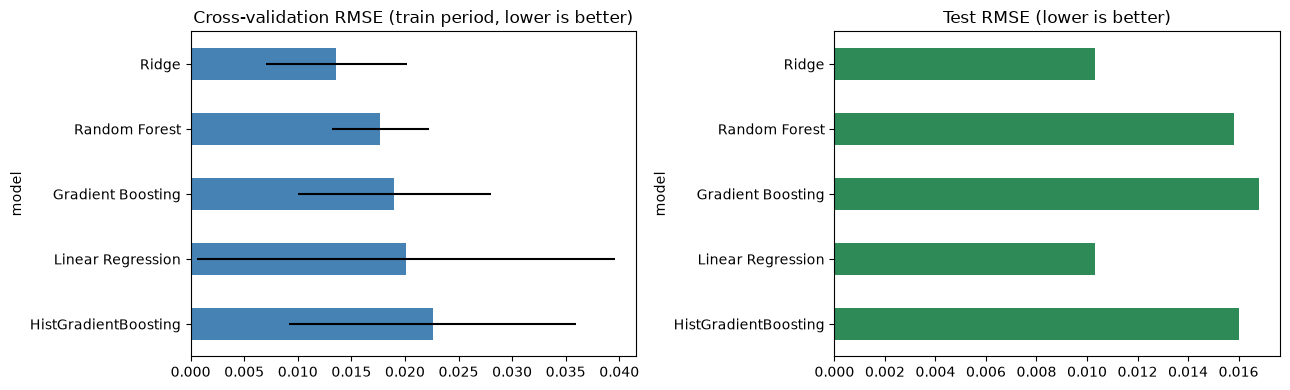

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cv_results["CV RMSE mean"].plot.barh(ax=ax[0], xerr=cv_results["CV RMSE std"], color="steelblue")
ax[0].set_title("Cross-validation RMSE (train period, lower is better)")
ax[0].invert_yaxis()
test_results["RMSE"].plot.barh(ax=ax[1], color="seagreen")
ax[1].set_title("Test RMSE (lower is better)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

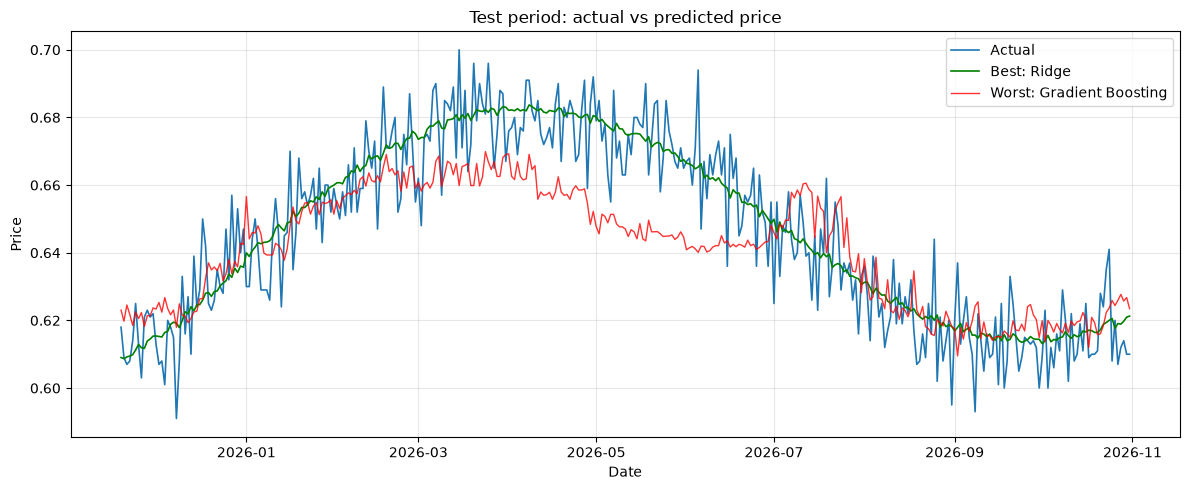

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(test["date"], y_test, label="Actual", linewidth=1.2)
plt.plot(test["date"], preds[best_name], label=f"Best: {best_name}", color="green", linewidth=1.2)
worst = test_results["RMSE"].idxmax()
plt.plot(test["date"], preds[worst], label=f"Worst: {worst}", color="red", linewidth=1, alpha=0.8)
plt.title("Test period: actual vs predicted price")
plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [16]:
Path("../models").mkdir(exist_ok=True)
bundle = {
    "model": models[best_name],
    "model_name": best_name,
    "features": FEATURES,
    "target": TARGET,
    "test_metrics": test_results.loc[best_name].to_dict(),
    "trained_through": str(train["date"].max().date()),
}
with open("../models/best_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

# quick reload check
with open("../models/best_model.pkl", "rb") as f:
    loaded = pickle.load(f)
same = np.allclose(loaded["model"].predict(X_test), preds[best_name])
print("Saved:", loaded["model_name"], "| reload gives same predictions:", same)

comparison = cv_results.join(test_results)
comparison.to_csv("../models/model_comparison.csv")
comparison

Saved: Ridge | reload gives same predictions: True


,CV RMSE mean,CV RMSE std,MAE,RMSE,R2
model,,,,,
Ridge,0.0136,0.0066,0.0081,0.0103,0.8552
Random Forest,0.0177,0.0045,0.0127,0.0158,0.6575
Gradient Boosting,0.0190,0.0090,0.0135,0.0168,0.6139
Linear Regression,0.0201,0.0195,0.0082,0.0103,0.8541
HistGradientBoosting,0.0226,0.0134,0.0128,0.0160,0.6474


In [1]:
import pickle

with open("../models/best_model.pkl", "rb") as f:
    bundle = pickle.load(f)

print(bundle["model_name"])
print(bundle["features"])
print(bundle["test_metrics"])

Ridge
['day_num', 'month', 'dayofweek', 'dayofyear', 'sin_year', 'cos_year', 'lag_1', 'lag_7', 'lag_30', 'roll_mean_7', 'roll_mean_30']
{'MAE': 0.0081, 'RMSE': 0.0103, 'R2': 0.8552}
